In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("C:/Users/LE BON MEC/Documents/cours MM/TFC/data/dataset_DGI_ready_ml.csv")

In [9]:
import pandas as pd

# Description générale du dataset

df['date_enregistrement'] = pd.to_datetime(df['date_enregistrement'], errors='coerce')

summary = pd.DataFrame({
    'Caractéristique': [
        'Nombre d\'observations',
        'Nombre total de variables',
        'Variables numériques',
        'Variables catégorielles',
        'Valeurs manquantes globales',
        'Période couverte',
    ],
    'Valeur': [
        df.shape[0],
        df.shape[1],
        df.select_dtypes(include=['number']).shape[1],
        df.select_dtypes(exclude=['number']).shape[1],
        f"{df.isna().sum().sum() / df.size * 100:.4f} %",
        f"du {df['date_enregistrement'].min().date()} au {df['date_enregistrement'].max().date()}",
    ]
})

print('=== Description générale du dataset ===')
print(summary.to_string(index=False))

=== Description générale du dataset ===
            Caractéristique                      Valeur
      Nombre d'observations                        6157
  Nombre total de variables                          37
       Variables numériques                          11
    Variables catégorielles                          26
Valeurs manquantes globales                    0.1313 %
           Période couverte du 2018-01-01 au 2023-12-30


In [2]:
df.shape
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6157 entries, 0 to 6156
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   plaque_immatriculation  6157 non-null   object 
 1   annee_fabrication       6157 non-null   int64  
 2   valeur_estimee_usd      6157 non-null   float64
 3   assurance               6157 non-null   object 
 4   controle_technique      6157 non-null   object 
 5   vignette                6157 non-null   object 
 6   taxe_circulation_usd    6157 non-null   float64
 7   taxe_stationnement_usd  6157 non-null   float64
 8   date_enregistrement     6157 non-null   object 
 9   nif                     5858 non-null   float64
 10  modele                  6157 non-null   object 
 11  type                    6157 non-null   object 
 12  genre                   6157 non-null   object 
 13  chassis                 6157 non-null   object 
 14  couleur                 6157 non-null   

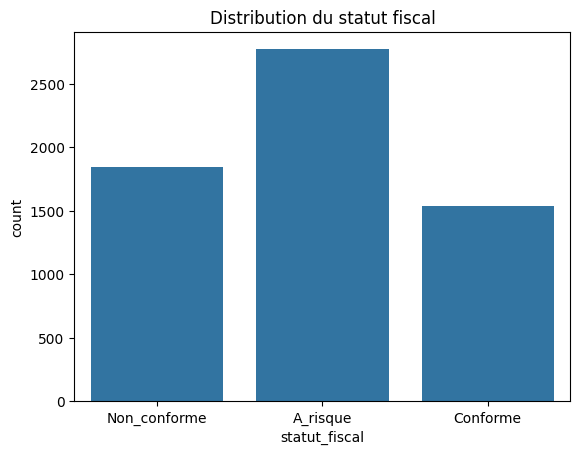

In [3]:
df['statut_fiscal'].value_counts()

sns.countplot(x='statut_fiscal', data=df)
plt.title("Distribution du statut fiscal")
plt.show()

In [4]:
df.describe()

,annee_fabrication,valeur_estimee_usd,taxe_circulation_usd,taxe_stationnement_usd,nif,puissance,age_vehicule,charge_fiscale,score,score_final,statut_fiscal_encoded
count,6157.000000,6157.000000,6157.000000,6157.000000,5858.000000,6157.000000,6157.000000,6157.000000,6157.000000,6157.000000,6157.000000
mean,2014.750528,10321.773406,283.867070,283.905789,551300.598839,130.223810,11.249472,567.772859,0.075921,1.062291,0.849764
std,6.615260,7013.222055,118.408994,119.139618,260831.689989,40.748268,6.615260,232.149471,0.040765,0.916788,0.852893
min,2002.000000,2000.184313,48.641296,48.645408,100014.000000,60.000000,0.000000,97.286704,0.008894,0.000000,0.000000
25%,2010.000000,5230.896227,191.563964,191.030849,329857.000000,95.000000,6.000000,384.726165,0.039805,0.226822,0.000000
50%,2015.000000,7680.402374,268.124940,269.536916,553593.500000,129.000000,11.000000,541.486146,0.073176,0.797424,1.000000
75%,2020.000000,13539.512597,363.526120,362.536085,775483.000000,165.000000,16.000000,724.114404,0.109269,1.760821,2.000000
max,2026.000000,29997.821243,699.698271,702.422347,999154.000000,200.000000,24.000000,1330.740137,0.173387,4.057217,2.000000


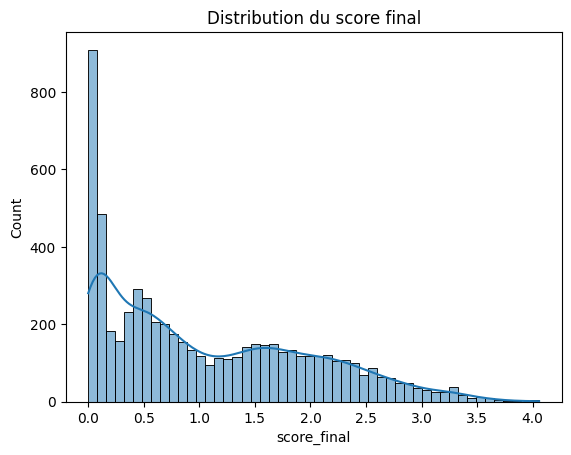

In [5]:
sns.histplot(df['score_final'], bins=50, kde=True)
plt.title("Distribution du score final")
plt.show()

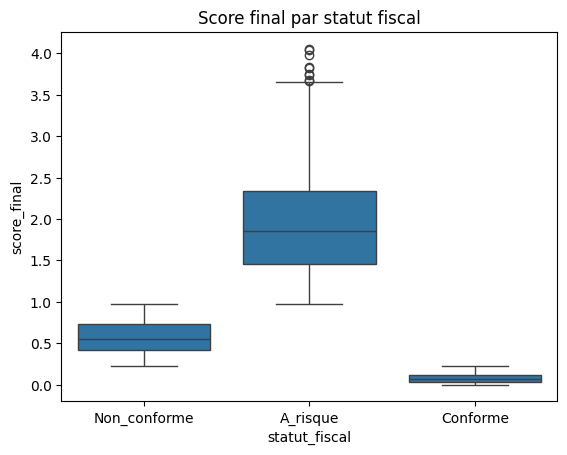

In [6]:
sns.boxplot(x='statut_fiscal', y='score_final', data=df)
plt.title("Score final par statut fiscal")
plt.show()

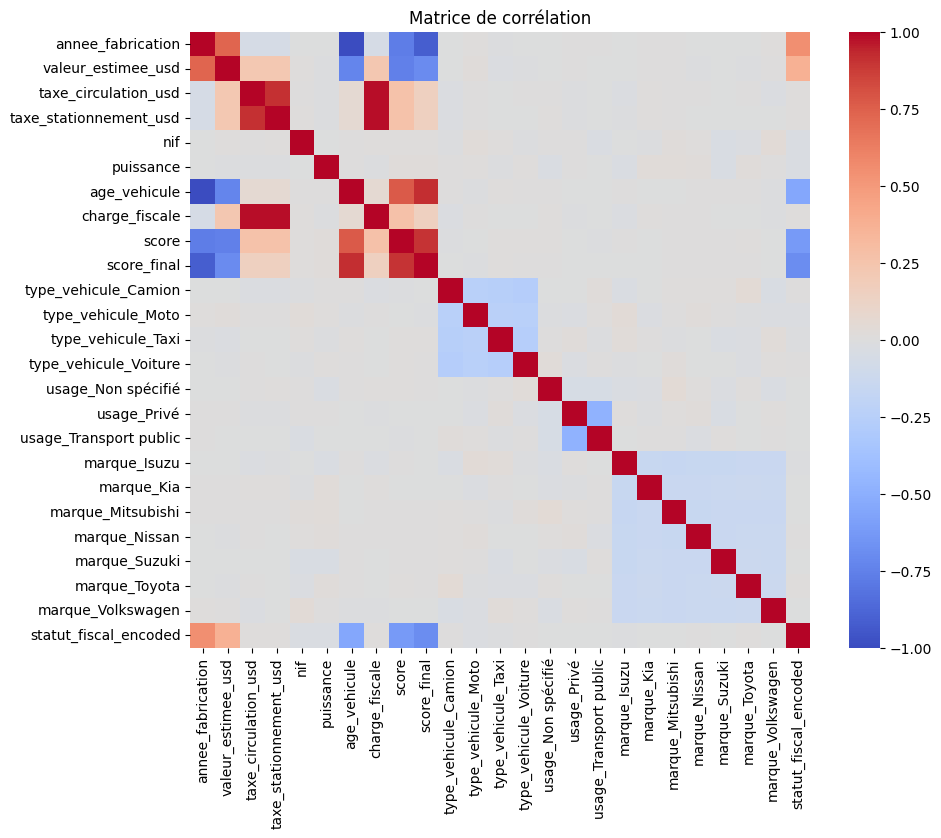

In [7]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=False, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

In [8]:
df.to_csv("C:/Users/LE BON MEC/Documents/cours MM/TFC/data/dataset_DGI_ready.csv", index=False)

In [3]:
import pandas as pd
import numpy as np

# Statistiques descriptives complètes des variables clés
num_cols = [
    'annee_fabrication', 'valeur_estimee_usd', 'puissance', 'age_vehicule',
    'taxe_circulation_usd', 'taxe_stationnement_usd', 'charge_fiscale',
    'score', 'score_final'
]

desc = df[num_cols].describe().T
desc['missing_pct'] = (df[num_cols].isna().mean() * 100).round(2)
print('=== Statistiques descriptives complètes ===')
print(desc.round(2).to_string())

cat_cols = ['type_vehicule_Camion', 'type_vehicule_Moto', 'type_vehicule_Taxi', 'type_vehicule_Voiture']
print('\n=== Répartition des types de véhicules ===')
print(df[cat_cols].sum().sort_values(ascending=False).to_string())


=== Statistiques descriptives complètes ===
                         count      mean      std      min      25%      50%       75%       max  missing_pct
annee_fabrication       6157.0   2014.75     6.62  2002.00  2010.00  2015.00   2020.00   2026.00          0.0
valeur_estimee_usd      6157.0  10321.77  7013.22  2000.18  5230.90  7680.40  13539.51  29997.82          0.0
puissance               6157.0    130.22    40.75    60.00    95.00   129.00    165.00    200.00          0.0
age_vehicule            6157.0     11.25     6.62     0.00     6.00    11.00     16.00     24.00          0.0
taxe_circulation_usd    6157.0    283.87   118.41    48.64   191.56   268.12    363.53    699.70          0.0
taxe_stationnement_usd  6157.0    283.91   119.14    48.65   191.03   269.54    362.54    702.42          0.0
charge_fiscale          6157.0    567.77   232.15    97.29   384.73   541.49    724.11   1330.74          0.0
score                   6157.0      0.08     0.04     0.01     0.04     0.07

=== Corrélations avec score_final et statut_fiscal_encoded ===
                        score_final  statut_fiscal_encoded
score_final                1.000000               0.691034
annee_fabrication          0.921123               0.553605
age_vehicule               0.921123               0.553605
score                      0.905947               0.623982
valeur_estimee_usd         0.697680               0.372864
statut_fiscal_encoded      0.691034               1.000000
charge_fiscale             0.152911               0.012400
taxe_circulation_usd       0.149703               0.010771
taxe_stationnement_usd     0.149170               0.013456
puissance                  0.018899               0.025104
nif                        0.011347               0.023568


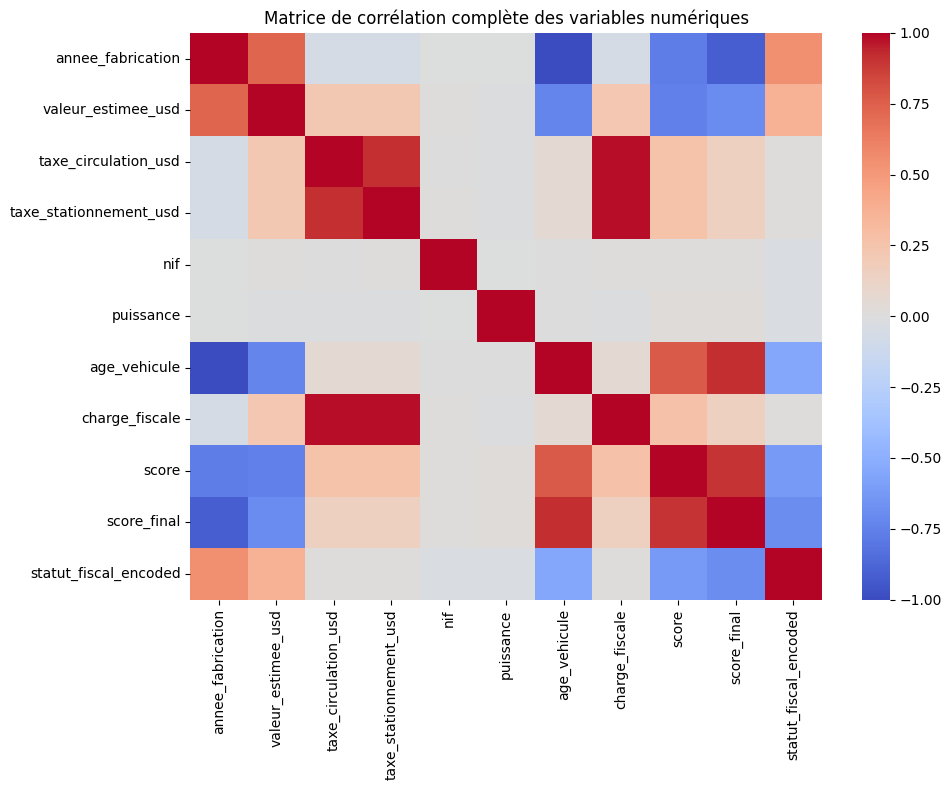

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Corrélations ciblées avec le score fiscal et la cible
num_df = df.select_dtypes(include=['number'])
corr = num_df.corr()

corr_target = corr[['score_final', 'statut_fiscal_encoded']].abs().sort_values('score_final', ascending=False)
print('=== Corrélations avec score_final et statut_fiscal_encoded ===')
print(corr_target.to_string())

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title('Matrice de corrélation complète des variables numériques')
plt.tight_layout()
plt.show()


In [6]:
import numpy as np

# Analyse des biais et redondances potentielles
missing_pct = df.isna().mean().sort_values(ascending=False)
class_dist = df['statut_fiscal'].value_counts(normalize=True)

corr_matrix = df.select_dtypes(include=['number']).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
redondant = [
    (row, col, val)
    for (row, col), val in upper.stack().items()
    if val >= 0.85
]

print('=== Taux de valeurs manquantes ===')
print(missing_pct[missing_pct > 0].round(4).to_string())
print('\n=== Distribution des classes ===')
print(class_dist.round(4).to_string())
print('\n=== Paires fortement corrélées (>= 0.85) ===')
for a, b, v in redondant[:20]:
    print(f'{a} <-> {b}: {v:.3f}')


=== Taux de valeurs manquantes ===
nif    0.0486

=== Distribution des classes ===
statut_fiscal
A_risque        0.4501
Non_conforme    0.2998
Conforme        0.2501

=== Paires fortement corrélées (>= 0.85) ===
annee_fabrication <-> age_vehicule: 1.000
annee_fabrication <-> score_final: 0.921
taxe_circulation_usd <-> taxe_stationnement_usd: 0.910
taxe_circulation_usd <-> charge_fiscale: 0.977
taxe_stationnement_usd <-> charge_fiscale: 0.977
age_vehicule <-> score_final: 0.921
score <-> score_final: 0.906


In [7]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Justification mathématique simple du score fiscal
num_features = ['annee_fabrication', 'valeur_estimee_usd', 'puissance', 'age_vehicule',
                'taxe_circulation_usd', 'taxe_stationnement_usd', 'charge_fiscale', 'score']
X = df[num_features]
y = df['score_final']

model = LinearRegression().fit(X, y)
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', key=lambda s: s.abs(), ascending=False)

print('=== Approximation linéaire du score fiscal ===')
print('R2 :', round(model.score(X, y), 4))
print('\n=== Coefficients les plus influents ===')
print(coef_df.to_string(index=False))


=== Approximation linéaire du score fiscal ===
R2 : 0.9649

=== Coefficients les plus influents ===
              Variable  Coefficient
                 score    16.212456
     annee_fabrication    -0.042175
          age_vehicule     0.042175
        charge_fiscale    -0.000398
taxe_stationnement_usd    -0.000243
  taxe_circulation_usd    -0.000155
             puissance     0.000093
    valeur_estimee_usd     0.000042
